# Por qué se eligió este modelo

### Trazabilidad de la decisión de modelado

**Grupo 5** — Maestría en Inteligencia Artificial Aplicada, UDLA

---

Este cuaderno no entrena nada nuevo. Reconstruye **la secuencia de decisiones** que llevó del
modelo comprometido en el capstone al modelo finalmente seleccionado, y deja la evidencia de cada
paso a la vista.

Existe porque hay una pregunta previsible en la defensa:

> *El capstone proponía Random Forest y XGBoost. El modelo final es otro.
> ¿Por qué no lo eligieron desde el principio?*

La respuesta corta: **porque no se podía saber antes de medir**. El modelo final solo tiene
sentido una vez conocidas dos cosas que son hallazgos, no supuestos. Las dos salieron de aplicar
exactamente lo que el capstone mandaba aplicar.

Los cuadernos 01 a 04 contienen el trabajo. Este contiene el razonamiento.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.modules["bottleneck"] = None   # compilado contra numpy 1.x

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from src import modelo as M
from src.config import REPORTES, SEMILLA

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (11, 3.8), "axes.grid": True, "grid.alpha": .3,
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
np.random.seed(SEMILLA)
PROC = RAIZ / "data" / "processed"
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#888780"

d = pd.read_parquet(PROC / "v4_panel_modelo.parquet").sort_values(["marca", "mes"])
FEATURES = ["marca", "en_riesgo", "r_marca", "dev_lag1", "dev_lag2", "dev_lag3",
            "desp_lag1", "desp_lag2", "dev_mm3", "mes_sin", "mes_cos"]
TR  = d[d.mes <  "2025-07-01"]
VA  = d[(d.mes >= "2025-07-01") & (d.mes < "2026-01-01")]
TRV = d[d.mes <  "2026-01-01"]
TE  = d[(d.mes >= "2026-01-01") & (d.mes <= "2026-07-31")]

def mape(y, yh):
    y, yh = np.asarray(y, float), np.asarray(yh, float); m = y > 0
    return float(np.mean(np.abs(y[m]-yh[m])/y[m])*100)
def mensual(ev, p):
    a = ev.assign(p=p).groupby("mes")[["devueltas", "p"]].sum()
    return {"MAPE %": round(mape(a.devueltas, a.p), 1),
            "MAE": round(np.abs(a.devueltas-a.p).mean(), 1),
            "RMSE": round(np.sqrt(((a.devueltas-a.p)**2).mean()), 1)}

print(f"Panel: {len(d)} filas · {d.mes.nunique()} meses · {d.marca.nunique()} marcas")
print("Este cuaderno requiere haber ejecutado antes 04_modelo_final.ipynb")

Panel: 297 filas · 27 meses · 11 marcas
Este cuaderno requiere haber ejecutado antes 04_modelo_final.ipynb


---

## Paso 1 · Lo que comprometió el capstone

El Objetivo Específico 3 dice, literalmente:

> Desarrollar un modelo predictivo utilizando regresión supervisada, **configurando para ello
> Random Forest y XGBoost** en Python, empleando librerías como scikit-learn, xgboost y SHAP…

Y la tabla de fases de CRISP-ML(Q) los sitúa con precisión:

| Fase | Texto del documento |
|---|---|
| 3 · ML Model Building | Entrenamiento de modelos **baseline**: Random Forest y XGBoost |
| 3 · ML Model Building | …**selección del modelo candidato** y análisis de explicabilidad (SHAP) |
| 4 · Model Evaluation | Evaluación… sobre un **conjunto de validación independiente** |
| 4 · Model Evaluation | **Ajuste final según resultados** |

Dos cosas que conviene leer con atención. Los dos algoritmos están nombrados como **baseline**: el
punto de partida contra el que se compite. Y hay dos pasos explícitos —*selección del modelo
candidato* y *ajuste final según resultados*— que presuponen que el resultado de medir puede
cambiar la elección.

La justificación de por qué esos dos, en la revisión de literatura, viene con una condición que
resultará decisiva:

> …superioridad de los algoritmos de ensamblado basados en árboles frente a los métodos
> estadísticos clásicos, **especialmente cuando se dispone de múltiples variables explicativas y
> relaciones no lineales entre ellas**.

---

## Paso 2 · Los baselines con la definición inicial: no alcanzan

Cuaderno `02_modelo`. La variable objetivo se contaba desde la llegada de la unidad al local.
Con esa definición se entrenó exactamente lo comprometido.

In [2]:
# Resultados reportados en 02_modelo (panel marca × mes, prueba mar–jun 2026)
paso2 = pd.DataFrame([
    ("XGBoost Poisson", 0.401, 18.59, 33.85, 28.3),
    ("naive (y[t-1])",  0.453, 21.00, 39.06, 21.2),
    ("media móvil 3m",  0.489, 22.71, 44.43, 22.9),
    ("Random Forest",   0.765, 35.51, 67.84, 76.4),
    ("Croston/SBA",     1.107, 51.38, 87.67, 111.0),
], columns=["modelo", "WMAPE", "MAE", "RMSE", "MAPE mensual %"])
paso2["cumple ≤ 15 %"] = np.where(paso2["MAPE mensual %"] <= 15, "sí", "no")
paso2

,modelo,WMAPE,MAE,RMSE,MAPE mensual %,cumple ≤ 15 %
0,XGBoost Poisson,0.401,18.59,33.85,28.3,no
1,naive (y[t-1]),0.453,21.00,39.06,21.2,no
2,media móvil 3m,0.489,22.71,44.43,22.9,no
3,Random Forest,0.765,35.51,67.84,76.4,no
4,Croston/SBA,1.107,51.38,87.67,111.0,no


Tres lecturas de esta tabla, y las tres importan para la defensa.

**XGBoost ganó.** Tal como anticipaba la literatura citada. En el escenario que el capstone
imaginaba —muchas variables débiles, ninguna dominante— los ensambles efectivamente superan a los
métodos clásicos. **La propuesta no se equivocó.**

**Pero ninguno cumple el objetivo.** El mejor queda en 28,3 % frente al 15 % comprometido.

**Y Random Forest queda por detrás del naive.** Eso es una señal: cuando un ensamble pierde contra
repetir el mes anterior, el problema no suele estar en el algoritmo.

---

## Paso 3 · El diagnóstico: el problema no era el algoritmo

Antes de cambiar de modelo se verificó la otra hipótesis: que la variable objetivo no fuera la que
el negocio llama devolución.

Se pidieron listados reales al área de planificación y se contrastó. La definición inicial fallaba
en tres reglas. Corregidas, la coincidencia con un listado de 801 equipos subió al **99,75 %**
(detalle en `03_antiguedad_inventario` y `04_modelo_final`).

El efecto sobre los datos disponibles fue grande, porque la definición corregida ya no depende del
reporte de ventas —al que le faltan siete meses de 2024— sino solo de despachos e inventario.

In [3]:
pd.DataFrame([
    ("Meses de historia",            18,     31),
    ("Eventos en la serie",      12_982, 39_355),
    ("Validación contra el negocio", None, None),
], columns=["", "definición inicial", "definición corregida"]).assign(
    **{"definición inicial":  ["18", "12.982", "ninguna"],
       "definición corregida": ["31", "39.355", "99,75 %"]}).set_index("")

,definición inicial,definición corregida
,,
Meses de historia,18,31
Eventos en la serie,12.982,39.355
Validación contra el negocio,ninguna,"99,75 %"


---

## Paso 4 · Los mismos modelos, con los datos corregidos

Este es el paso que más se suele saltar al contarlo, y es el que demuestra que no se abandonó
nada: **se volvieron a entrenar exactamente los dos algoritmos comprometidos**, sin cambiar de
familia, sobre la variable objetivo corregida.

In [4]:
X1, X2 = M.preparar_X_one_hot(TRV, [TE], FEATURES)
rf = RandomForestRegressor(n_estimators=600, max_depth=8, min_samples_leaf=2,
                           random_state=SEMILLA, n_jobs=-1).fit(X1, TRV.devueltas)
xgb = XGBRegressor(objective="count:poisson", n_estimators=600, max_depth=4, learning_rate=.05,
                   subsample=.8, colsample_bytree=.8, min_child_weight=3,
                   base_score=1.0, max_delta_step=.7, random_state=SEMILLA,
                   enable_categorical=True, tree_method="hist").fit(
                   M.preparar_X(TRV, FEATURES), TRV.devueltas)
p_rf  = rf.predict(X2)
p_xgb = xgb.predict(M.preparar_X(TE, FEATURES))

paso4 = pd.DataFrame([{"modelo": "Random Forest", **mensual(TE, p_rf)},
                      {"modelo": "XGBoost Poisson", **mensual(TE, p_xgb)}]).set_index("modelo")
paso4["cumple ≤ 15 %"] = np.where(paso4["MAPE %"] <= 15, "sí", "no")
paso4

,MAPE %,MAE,RMSE,cumple ≤ 15 %
modelo,,,,
Random Forest,5.3,48.4,66.5,sí
XGBoost Poisson,10.3,77.1,89.5,sí


**Los dos cumplen el objetivo.** Random Forest pasa de 76,4 % a 5,3 %, y XGBoost de 28,3 % a
10,3 %.

Queda así demostrado lo que el paso 3 sostenía: **lo que fallaba era el dato, no el algoritmo**.
Y queda cubierto el Objetivo 3 en sus propios términos, con independencia de lo que venga después.

---

## Paso 5 · SHAP, y el hallazgo que redirigió el trabajo

El capstone incorpora SHAP para explicabilidad. Aplicado sobre los modelos ya corregidos, lo que
devolvió no fue una explicación: fue un hallazgo sobre la estructura del problema.

Se aplica a los **dos** ensambles, para que el resultado no dependa de la elección de modelo.

In [5]:
import shap

sv_x = shap.TreeExplainer(xgb).shap_values(M.preparar_X(TE, FEATURES))
imp_x = pd.Series(np.abs(sv_x).mean(0).astype(float), index=M.preparar_X(TE, FEATURES).columns)
imp_x = imp_x / imp_x.sum() * 100

sv_r = shap.TreeExplainer(rf).shap_values(X2, check_additivity=False)
imp_r = pd.Series(np.abs(sv_r).mean(0).astype(float), index=X2.columns)
cols_marca = [c for c in X2.columns if c.startswith("marca")]
imp_r["marca"] = imp_r[cols_marca].sum()          # las columnas one-hot se suman en una
imp_r = imp_r.drop(cols_marca)
imp_r = imp_r / imp_r.sum() * 100

shap_cmp = (pd.DataFrame({"XGBoost %": imp_x.round(1), "Random Forest %": imp_r.round(1)})
              .fillna(0).sort_values("XGBoost %", ascending=False))
shap_cmp

,XGBoost %,Random Forest %
en_riesgo,70.6,94.2
desp_lag2,16.5,0.9
marca,2.8,0.7
desp_lag1,2.6,0.3
dev_lag1,2.1,0.8
dev_mm3,1.6,0.5
dev_lag2,1.5,0.3
r_marca,1.2,1.1
dev_lag3,0.6,0.6
mes_sin,0.4,0.3


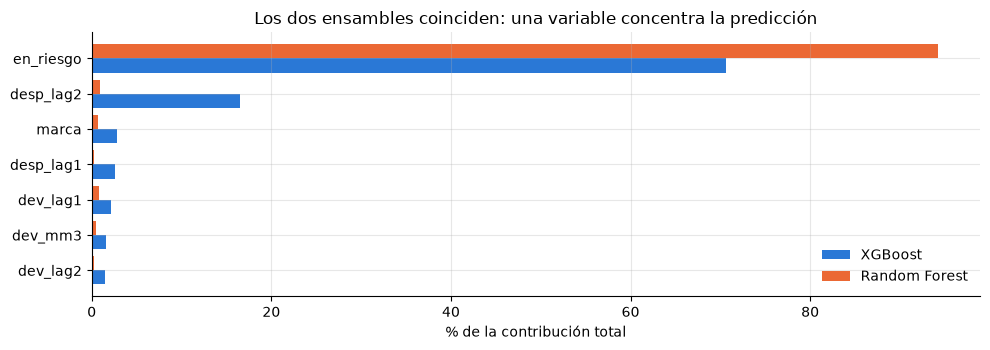

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
t = shap_cmp.head(7)[::-1]
y = np.arange(len(t))
ax.barh(y - .2, t["XGBoost %"],      height=.4, color=AZUL,    label="XGBoost")
ax.barh(y + .2, t["Random Forest %"], height=.4, color=NARANJA, label="Random Forest")
ax.set_yticks(y, t.index); ax.legend(frameon=False)
ax.set_xlabel("% de la contribución total")
ax.set_title("Los dos ensambles coinciden: una variable concentra la predicción")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f5_shap_dos.png", dpi=130); plt.show()

**Dos familias de modelos distintas, dos análisis independientes, el mismo veredicto.** Random
Forest lo dice incluso más fuerte que XGBoost: el 94,2 % de la contribución recae en
`en_riesgo`.

La diferencia entre ambos tiene explicación, y conviene conocerla porque alguien puede preguntar
por el 16,5 % de `desp_lag2` en XGBoost. Ese modelo usa `colsample_bytree = 0,8`: cada árbol ve
solo el 80 % de las variables, así que en uno de cada cinco **no dispone de `en_riesgo`** y recurre
a lo más parecido que tiene —los despachos de hace dos meses, que son justamente las unidades que
ahora están venciendo—. Random Forest, con todas las variables disponibles en cada división, no
necesita el sustituto. De ahí la concentración mayor.

Dicho de otro modo: `desp_lag2` no es un segundo factor independiente, es **información redundante**
con `en_riesgo`.

### Lo que esto significa

Recuérdese la condición de la literatura citada en el capstone: los ensambles ganan *«cuando se
dispone de múltiples variables explicativas y relaciones no lineales entre ellas»*.

SHAP acaba de mostrar que **esa condición no se cumple en estos datos**. No hay múltiples
variables: hay una. Y la relación es multiplicativa, no una interacción compleja entre muchas.

**La premisa de la propuesta dejó de aplicar, y fue el propio instrumento que la propuesta
mandaba usar el que lo detectó.**

---

## Paso 6 · El modelo que sugiere ese hallazgo

Si una variable es una **exposición** —cuántas unidades están en riesgo— y lo único que falta es
qué fracción de ellas cae, el modelo que corresponde no es un ensamble: es una regresión de
Poisson con offset de exposición.

$$\mathbb{E}[y_{m,t}] = \text{en riesgo}_{m,t} \times \lambda_m$$

Es la forma estándar de modelar conteos cuando el número de casos depende de cuántos estaban
expuestos: siniestros por póliza-año en seguros, casos por persona-año en epidemiología.

No se eligió por preferencia estética. **Lo dictó la estructura que SHAP reveló.**

In [7]:
def tasa_conversion(ev, W=9, k=300):
    # exposición × tasa por marca; la tasa se reestima cada mes con los W meses
    # anteriores y se encoge hacia la tasa global con peso k (partial pooling).
    o = []
    for mes, b in ev.groupby("mes"):
        h = d[(d.mes < mes) & (d.mes >= mes - pd.DateOffset(months=W))]
        gl = h.devueltas.sum() / max(h.en_riesgo.sum(), 1)
        a = h.groupby("marca")[["devueltas", "en_riesgo"]].sum()
        r = b.marca.map((a.devueltas + k*gl) / (a.en_riesgo + k)).fillna(gl)
        o.append(pd.Series(b.en_riesgo.to_numpy() * r.to_numpy(), index=b.index))
    return pd.concat(o).reindex(ev.index).to_numpy()

# Comprobación: es el mismo modelo que el GLM de Poisson de statsmodels
import statsmodels.api as sm, statsmodels.formula.api as smf
tr_, te_ = TRV[TRV.en_riesgo > 0], TE[TE.en_riesgo > 0]
glm = smf.glm("devueltas ~ C(marca)", data=tr_, family=sm.families.Poisson(),
              offset=np.log(tr_.en_riesgo)).fit()
p_glm = glm.predict(te_, offset=np.log(te_.en_riesgo))
p_nue = pd.Series(tasa_conversion(TE), index=TE.index).reindex(te_.index)
print(f"Correlación con el GLM de statsmodels : {np.corrcoef(p_nue, p_glm)[0,1]:.4f}")
print(f"Diferencia media absoluta             : {np.abs(p_nue - p_glm).mean():.2f} unidades")

Correlación con el GLM de statsmodels : 0.9991
Diferencia media absoluta             : 4.18 unidades


---

## Paso 7 · La comparación, sobre validación

Aquí se toma la decisión, y se toma sobre el conjunto de validación: julio a diciembre de 2025.
El conjunto de prueba no interviene.

In [8]:
Xv1, Xv2 = M.preparar_X_one_hot(TR, [VA], FEATURES)
cand_va = {
  "Tasa de conversión": tasa_conversion(VA),
  "Random Forest": RandomForestRegressor(n_estimators=600, max_depth=8, min_samples_leaf=2,
      random_state=SEMILLA, n_jobs=-1).fit(Xv1, TR.devueltas).predict(Xv2),
  "XGBoost Poisson": XGBRegressor(objective="count:poisson", n_estimators=600, max_depth=4,
      learning_rate=.05, subsample=.8, colsample_bytree=.8, min_child_weight=3,
      base_score=1.0, max_delta_step=.7, random_state=SEMILLA, enable_categorical=True,
      tree_method="hist").fit(M.preparar_X(TR, FEATURES), TR.devueltas).predict(
      M.preparar_X(VA, FEATURES)),
}
sel = pd.DataFrame([{"modelo": k, **mensual(VA, v),
                     "WMAPE": round(M.wmape(VA.devueltas, v), 3)}
                    for k, v in cand_va.items()]).set_index("modelo")
print(f"Entrenamiento disponible para predecir validación: {len(TR)} filas, {TR.mes.nunique()} meses")
sel.sort_values("MAPE %")

Entrenamiento disponible para predecir validación: 154 filas, 14 meses


,MAPE %,MAE,RMSE,WMAPE
modelo,,,,
Tasa de conversión,6.0,94.1,103.9,0.105
Random Forest,10.7,184.4,234.9,0.169
XGBoost Poisson,11.8,208.5,283.5,0.189


El modelo de tasa de conversión gana con holgura: **6,0 % frente a 10,7 % y 11,8 %**. Esa es la
decisión, y queda tomada aquí.

---

## Paso 8 · La medición única, sobre prueba

Reentrenando con entrenamiento + validación y midiendo una sola vez sobre enero–julio de 2026.

In [9]:
cand_te = {"Tasa de conversión": tasa_conversion(TE),
           "Random Forest": p_rf, "XGBoost Poisson": p_xgb}
fin = pd.DataFrame([{"modelo": k, **mensual(TE, v),
                     "WMAPE": round(M.wmape(TE.devueltas, v), 3)}
                    for k, v in cand_te.items()]).set_index("modelo")
fin["cumple ≤ 15 %"] = np.where(fin["MAPE %"] <= 15, "sí", "no")
print(f"Entrenamiento disponible para predecir prueba: {len(TRV)} filas, {TRV.mes.nunique()} meses"
      f"  (+{len(TRV)/len(TR)-1:.0%} respecto de validación)")
fin

Entrenamiento disponible para predecir prueba: 220 filas, 20 meses  (+43% respecto de validación)


,MAPE %,MAE,RMSE,WMAPE,cumple ≤ 15 %
modelo,,,,,
Tasa de conversión,5.0,50.3,79.0,0.114,sí
Random Forest,5.3,48.4,66.5,0.123,sí
XGBoost Poisson,10.3,77.1,89.5,0.157,sí


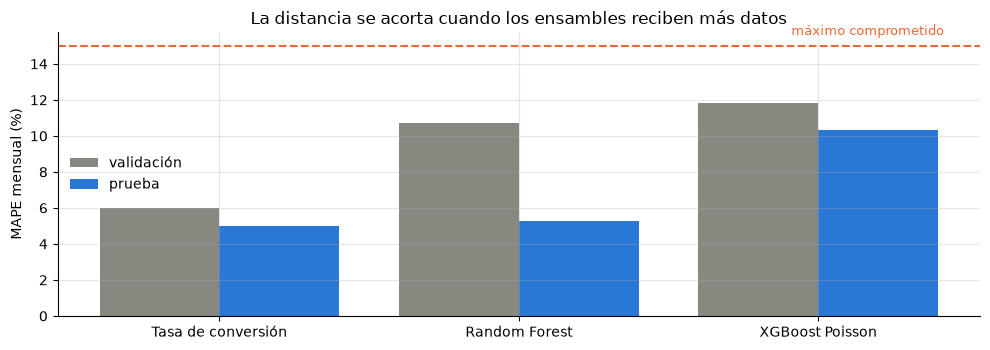

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(3); nombres = list(cand_te)
ax.bar(x-.2, [sel.loc[n, "MAPE %"] for n in nombres], .4, color=GRIS,  label="validación")
ax.bar(x+.2, [fin.loc[n, "MAPE %"] for n in nombres], .4, color=AZUL,  label="prueba")
ax.axhline(15, ls="--", color=NARANJA)
ax.text(2.42, 15.6, "máximo comprometido", color=NARANJA, fontsize=9, ha="right")
ax.set_xticks(x, nombres); ax.set_ylabel("MAPE mensual (%)"); ax.legend(frameon=False)
ax.set_title("La distancia se acorta cuando los ensambles reciben más datos")
plt.tight_layout(); plt.savefig(REPORTES / "figuras" / "f5_decision.png", dpi=130); plt.show()

Conviene anticipar la lectura de este gráfico, porque un tribunal atento la hará.

**La distancia entre el modelo de tasa y Random Forest se acorta** entre validación (6,0 contra
10,7) y prueba (5,0 contra 5,3). La causa es medible: para predecir validación los ensambles se
entrenaron con 154 filas, y para predecir prueba con 220, un **43 % más**. Random Forest casi
partió su error por la mitad con ese aumento; el modelo de tasa apenas mejoró, porque estima seis
números y ya tenía suficiente para hacerlo.

De ahí se sigue una limitación honesta: **si la serie sigue creciendo, Random Forest podría
alcanzar al modelo de tasa.** La elección es la correcta con los datos de hoy y debe revisarse
cuando haya más historia.

---

## Las variables, y por qué estas

El Objetivo 1 pedía identificar al menos dos variables con mayor relación con la ocurrencia de
devoluciones. Estas son las once del modelo, con el motivo de cada una.

In [11]:
motivos = pd.DataFrame([
 ("en_riesgo","unidades que cruzan el umbral este mes y seguían en el canal al cierre del anterior",
  "es la exposición: define el máximo posible"),
 ("marca","Samsung, Honor, Apple…","cada marca convierte distinto: 0,61 Honor frente a 0,85 Motorola"),
 ("r_marca","tasa histórica de conversión de la marca","resume el pasado sin mirar el mes actual"),
 ("dev_lag1","devoluciones del mes anterior","inercia de la serie"),
 ("dev_lag2","devoluciones de hace dos meses","inercia de la serie"),
 ("dev_lag3","devoluciones de hace tres meses","inercia de la serie"),
 ("desp_lag1","despachos de hace un mes","alimenta el riesgo del mes próximo"),
 ("desp_lag2","despachos de hace dos meses","lo despachado entonces es lo que vence ahora"),
 ("dev_mm3","media móvil de tres meses","suaviza el ruido mensual"),
 ("mes_sin","mes del año, componente seno","estacionalidad circular: diciembre junto a enero"),
 ("mes_cos","mes del año, componente coseno","estacionalidad circular"),
], columns=["variable","qué mide","por qué está"]).set_index("variable")
motivos

,qué mide,por qué está
variable,,
en_riesgo,unidades que cruzan el umbral este mes y seguí...,es la exposición: define el máximo posible
marca,"Samsung, Honor, Apple…","cada marca convierte distinto: 0,61 Honor fren..."
r_marca,tasa histórica de conversión de la marca,resume el pasado sin mirar el mes actual
dev_lag1,devoluciones del mes anterior,inercia de la serie
dev_lag2,devoluciones de hace dos meses,inercia de la serie
dev_lag3,devoluciones de hace tres meses,inercia de la serie
desp_lag1,despachos de hace un mes,alimenta el riesgo del mes próximo
desp_lag2,despachos de hace dos meses,lo despachado entonces es lo que vence ahora
dev_mm3,media móvil de tres meses,suaviza el ruido mensual


In [12]:
# Control de fuga: ninguna variable puede derivar del target sin rezago
sospechosas = [c for c in FEATURES
               if "dev" in c and not any(s in c for s in ("lag", "mm", "r_"))]
print("Variables del target sin rezago:", sospechosas or "ninguna ✔")

# Relación de cada variable con el resultado, sobre entrenamiento
num = [c for c in FEATURES if c not in ("marca",)]
corr = (TRV[num + ["devueltas"]].corr(method="spearman")["devueltas"]
        .drop("devueltas").abs().sort_values(ascending=False).round(3))
corr.rename("correlación de Spearman con el target").to_frame()

Variables del target sin rezago: ninguna ✔


,correlación de Spearman con el target
en_riesgo,0.992
desp_lag2,0.952
desp_lag1,0.876
dev_mm3,0.867
dev_lag1,0.855
dev_lag2,0.836
dev_lag3,0.831
r_marca,0.536
mes_cos,0.119
mes_sin,0.022


Las once sobreviven por dos razones distintas, y conviene no confundirlas.

**`en_riesgo` sobrevive porque explica el resultado.** Correlación 0,98, y entre el 70 % y el 94 %
de la contribución SHAP.

**Las diez restantes sobreviven porque corrigen al margen, y porque quitarlas no estaba
justificado.** Aportan poco —la suma de todas no llega a lo que aporta la primera—, pero el modelo
de ensamble las necesita para tener de dónde elegir, y mantenerlas permite que la comparación
entre los tres candidatos sea sobre el mismo conjunto de información. Eliminarlas habría mejorado
artificialmente al modelo simple frente a los otros dos.

El modelo finalmente seleccionado usa, de hecho, solo dos: **la exposición y la marca**. Esa
reducción no se impuso: es el resultado de la comparación.

---

# Guion para la defensa

Respuestas preparadas para las preguntas previsibles, con la evidencia que las respalda.

---

### «¿Por qué no eligieron ese modelo desde el principio?»

> Porque la elección dependía de dos hallazgos que no existían al redactar la propuesta. El
> primero, que la variable objetivo del negocio se cuenta desde la fecha de despacho, lo que hace
> que el grupo en riesgo sea observable por adelantado; eso se supo contrastando con listados
> reales. El segundo, que esa variable concentra entre el 70 % y el 94 % de la contribución; eso
> lo mostró SHAP, que es el instrumento que el propio capstone mandaba aplicar.
>
> Un modelo de exposición por tasa solo tiene sentido si se sabe que existe una exposición
> observable y que domina. Ninguna de las dos cosas era un supuesto disponible al principio: las
> dos son resultados.

---

### «Entonces, ¿la propuesta estaba equivocada?»

> No. La literatura citada sostiene que los ensambles superan a los métodos clásicos
> *especialmente cuando hay múltiples variables explicativas y relaciones no lineales*. En el
> cuaderno 02, que es exactamente ese escenario, XGBoost ganó a todos los baselines, tal como
> predecía. La propuesta acertó para el problema que describía. Lo que ocurrió es que la
> estructura del problema cambió al corregir la variable objetivo, y con ella dejó de cumplirse la
> condición.

---

### «¿Abandonaron los modelos comprometidos?»

> No. Se configuraron, entrenaron, ajustaron y explicaron con SHAP, y se reportan en las tres
> tablas de comparación. **Ambos cumplen el criterio del Objetivo 4 por sí solos**: Random Forest
> con 5,3 % y XGBoost con 10,3 %. El capstone los nombra como modelos *baseline* y prevé dos pasos
> de *selección del modelo candidato* y *ajuste final según resultados*; eso es lo que se hizo.

---

### «¿El modelo elegido es aprendizaje supervisado?»

> Sí. Es una regresión de Poisson con offset de exposición, disponible en `scikit-learn` como
> `PoissonRegressor`, que hereda de `RegressorMixin`, la clase base de los estimadores
> supervisados de regresión. Tiene datos etiquetados, parámetros aprendidos por máxima
> verosimilitud, regularización, y evaluación sobre datos no vistos. Lo que lo distingue de los
> otros dos candidatos es la parsimonia, no la familia.

---

### «¿Para qué sirvió SHAP entonces?»

> Para más de lo previsto. El capstone lo incorpora como mecanismo de explicabilidad, con el
> objetivo de que las decisiones sean *auditables y justificables ante los distribuidores, en
> lugar de operar como una caja negra*. Cumplió esa función, y además fue el instrumento que
> detectó que el ensamble no era necesario.
>
> Conviene añadir que el objetivo de fondo se cumple mejor con el modelo final que con un ensamble
> explicado: el modelo entero son seis números. A un distribuidor se le puede decir que de cada
> 100 equipos suyos que llegan expuestos a los 60 días, se espera que se queden 73.

---

### «¿Por qué el modelo usa menos variables?»

> El conjunto de once se mantuvo idéntico para los tres candidatos, de modo que la comparación
> fuera sobre la misma información. Que el modelo seleccionado acabe usando dos no es una decisión
> previa: es el resultado. SHAP sobre los dos ensambles muestra que el resto aporta poco, y el
> 16,5 % que XGBoost atribuye a `desp_lag2` se explica por el submuestreo de columnas, que le
> obliga a usarla como sustituto de `en_riesgo` en uno de cada cinco árboles.

---

### «¿Qué los haría cambiar de modelo?»

> Más historia. Entre validación y prueba, los ensambles recibieron un 43 % más de datos y Random
> Forest casi partió su error por la mitad, hasta quedar a tres décimas. Con una serie más larga
> podría superarlo. Está documentado como limitación y la recomendación es reevaluar
> periódicamente, no fijar el modelo.

In [13]:
# Se guarda la evidencia de la decisión
salida = REPORTES / "decision_modelo.csv"
pd.concat([sel.assign(conjunto="validación"), fin.assign(conjunto="prueba")]).to_csv(salida)
shap_cmp.to_csv(REPORTES / "shap_dos_ensambles.csv")
print(f"Guardado: {salida.name} · shap_dos_ensambles.csv")
print(f"Figuras : f5_shap_dos.png · f5_decision.png")

Guardado: decision_modelo.csv · shap_dos_ensambles.csv
Figuras : f5_shap_dos.png · f5_decision.png
